[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/xvillarreald-max/PROCESAMIENTO-DIGITAL-DE-IMAGENES-Y-LABORATORIO/blob/main/PDIP8.ipynb)

# Práctica 8 – Aplicación de Filtros
**Universidad Autónoma de Nuevo León – Facultad de Ingeniería Mecánica y Eléctrica**
Procesamiento Digital de Imágenes · Semestre Enero–Junio 2026

| Integrante | Matrícula |
|---|---|
| Andrea Sofía Cantú Trejo | 2120574 |
|Ximena Villareal Dávila	| 2177714 |
|Karen Melissa Morales Moya	| 2043909 |
|Julia Aracely Muñoz González	| 2094919 |


Brigada:309 Día y hora:Miércoles N5


## Objetivo

Aplicar filtros convolucionales y filtros en el dominio de la frecuencia sobre imágenes médicas, variando tamaños de kernel, máscaras y radios de corte para comparar sus efectos sobre la imagen.

## Imágenes utilizadas

Radiografías de tórax del dataset *Chest X-Ray Images (Pneumonia)* de Kaggle:
https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia

- Parte I: una radiografía de tórax normal.
- Parte II: una radiografía normal y una con neumonía.

In [4]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 100

In [5]:
RUTA_1 = "IM-0115-0001.jpeg"
RUTA_2 = "person1_bacteria_1.jpeg"
TAM = (512, 512)

def cargar(ruta):
    im = cv2.imread(ruta, cv2.IMREAD_GRAYSCALE)
    if im is None:
        raise FileNotFoundError(ruta)
    return cv2.resize(im, TAM)

def mostrar(imgs, titulos, cols=3, size=4):
    filas = int(np.ceil(len(imgs) / cols))
    fig, ejes = plt.subplots(filas, cols, figsize=(size * cols, size * filas))
    ejes = np.array(ejes).reshape(-1)
    for ax in ejes:
        ax.axis("off")
    for ax, im, t in zip(ejes, imgs, titulos):
        ax.imshow(im, cmap="gray")
        ax.set_title(t, fontsize=10)
    plt.tight_layout()
    plt.show()

In [ ]:
import os
import urllib.request

BASE = "https://raw.githubusercontent.com/xvillarreald-max/PROCESAMIENTO-DIGITAL-DE-IMAGENES-Y-LABORATORIO/main/"
for archivo in (RUTA_1, RUTA_2):
    if not os.path.exists(archivo):
        urllib.request.urlretrieve(BASE + archivo, archivo)
print(os.path.exists(RUTA_1), os.path.exists(RUTA_2))


---
# Parte I: Filtros con máscaras espaciales

## 1. Carga de la radiografía

Se carga la imagen en escala de grises y se redimensiona a 512x512 para que todos los filtros trabajen sobre el mismo tamaño.

(512, 512) uint8


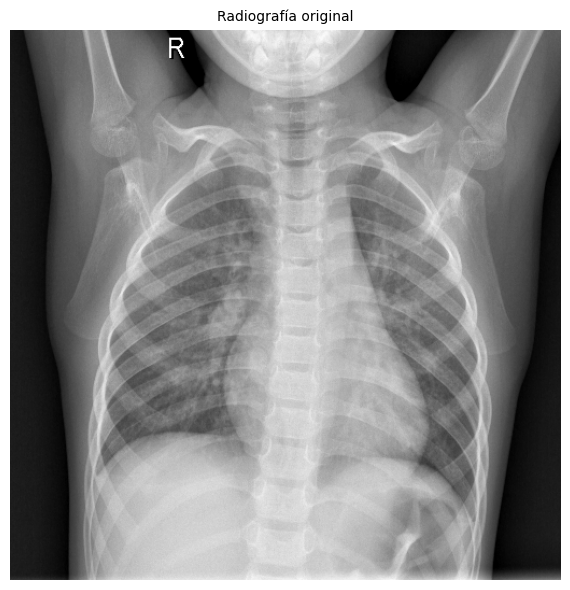

In [6]:
img = cargar(RUTA_1)
print(img.shape, img.dtype)
mostrar([img], ["Radiografía original"], cols=1, size=6)

## 2. Filtros de suavizado

Se aplican el filtro de media, el gaussiano y el de mediana con kernels de 3x3, 5x5 y 11x11.

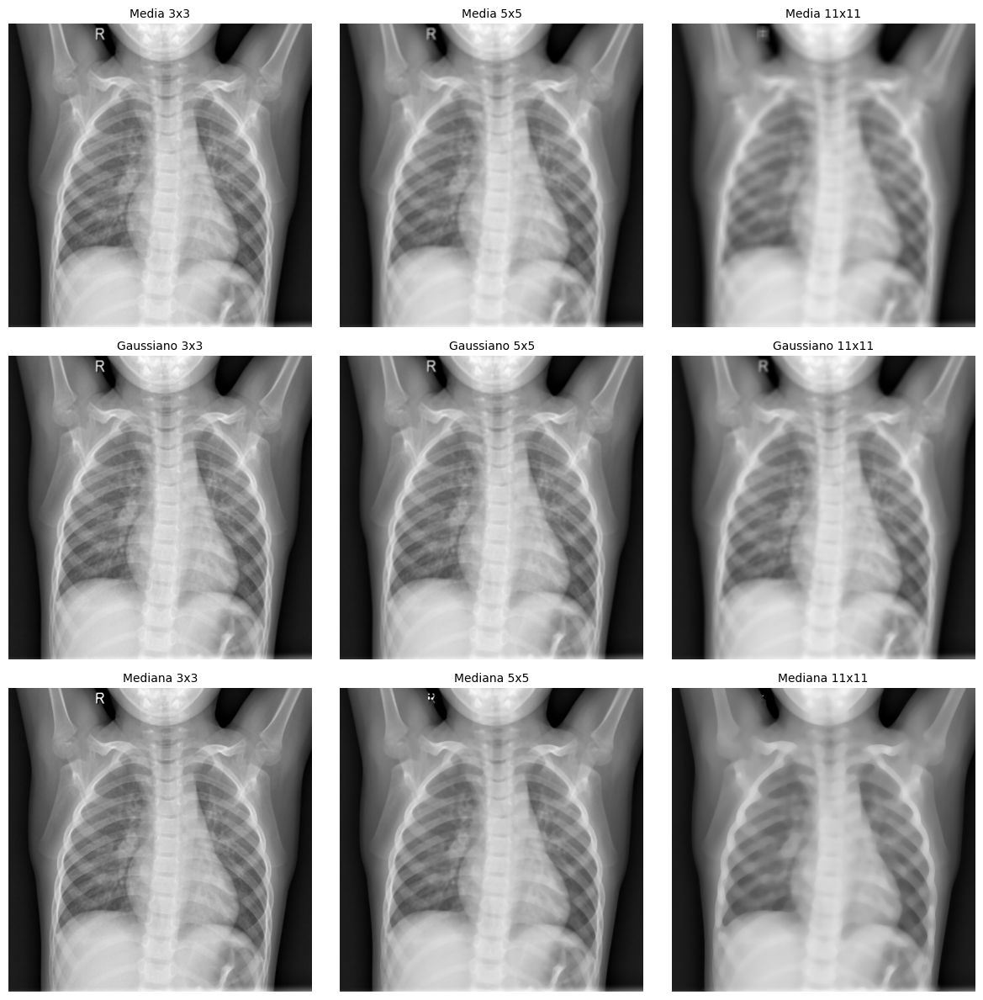

In [7]:
kernels = [3, 5, 11]
filtros = {
    "Media": lambda im, k: cv2.blur(im, (k, k)),
    "Gaussiano": lambda im, k: cv2.GaussianBlur(im, (k, k), 0),
    "Mediana": lambda im, k: cv2.medianBlur(im, k),
}

suavizadas = {}
imgs, titulos = [], []
for nombre, f in filtros.items():
    for k in kernels:
        r = f(img, k)
        suavizadas[(nombre, k)] = r
        imgs.append(r)
        titulos.append(f"{nombre} {k}x{k}")

mostrar(imgs, titulos, cols=3)

Para comparar de forma cuantitativa cuánto detalle se pierde con cada kernel se mide el error cuadrático medio (MSE) respecto a la imagen original y la varianza del Laplaciano como medida de nitidez.

In [8]:
print(f"{'Filtro':<12}{'Kernel':<8}{'MSE':>10}{'Nitidez (var Laplaciano)':>28}")
print(f"{'Original':<12}{'-':<8}{0:>10.2f}{cv2.Laplacian(img, cv2.CV_64F).var():>28.2f}")
for (nombre, k), r in suavizadas.items():
    mse = np.mean((img.astype(float) - r.astype(float)) ** 2)
    nit = cv2.Laplacian(r, cv2.CV_64F).var()
    print(f"{nombre:<12}{f'{k}x{k}':<8}{mse:>10.2f}{nit:>28.2f}")

Filtro      Kernel         MSE    Nitidez (var Laplaciano)
Original    -             0.00                      223.64
Media       3x3          14.39                       19.18
Media       5x5          31.45                        6.22
Media       11x11        70.05                        2.19
Gaussiano   3x3           9.29                       26.29
Gaussiano   5x5          15.91                       12.25
Gaussiano   11x11        37.12                        2.98
Mediana     3x3           8.55                      112.36
Mediana     5x5          29.13                       67.32
Mediana     11x11        56.40                       16.99


## 3. Filtros de detección de bordes

Se aplican Sobel en x, Sobel en y, Laplaciano y Kirsch con las máscaras estándar.

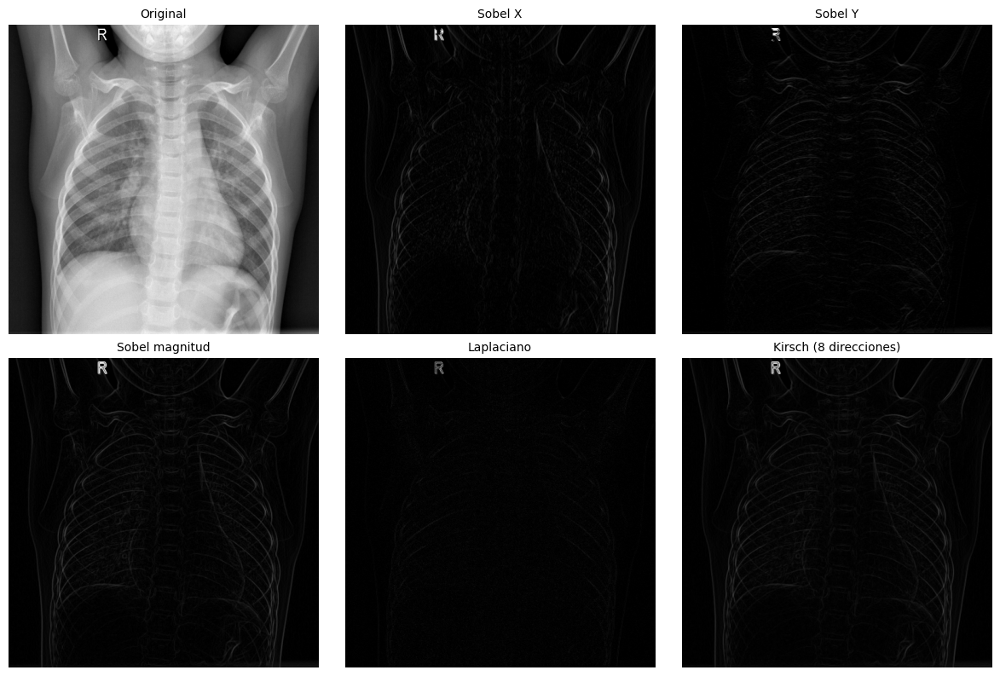

In [9]:
def conv(im, mascara):
    return cv2.filter2D(im.astype(np.float32), cv2.CV_32F, np.array(mascara, dtype=np.float32))

def norm(im):
    return cv2.normalize(np.abs(im), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

sobel_x = [[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]
sobel_y = [[-1, -2, -1], [0, 0, 0], [1, 2, 1]]
laplaciano = [[0, 1, 0], [1, -4, 1], [0, 1, 0]]

def kirsch_mascaras():
    base = np.array([[5, 5, 5], [-3, 0, -3], [-3, -3, -3]])
    anillo = [(0, 0), (0, 1), (0, 2), (1, 2), (2, 2), (2, 1), (2, 0), (1, 0)]
    mascaras = []
    for i in range(8):
        m = base.copy()
        for j, (r, c) in enumerate(anillo):
            m[anillo[(j + i) % 8]] = base[r, c]
        mascaras.append(m)
    return mascaras

def kirsch(im, mascaras):
    return np.max([conv(im, m) for m in mascaras], axis=0)

gx = conv(img, sobel_x)
gy = conv(img, sobel_y)
sobel_mag = np.sqrt(gx ** 2 + gy ** 2)
lap = conv(img, laplaciano)
kir = kirsch(img, kirsch_mascaras())

mostrar(
    [img, norm(gx), norm(gy), norm(sobel_mag), norm(lap), norm(kir)],
    ["Original", "Sobel X", "Sobel Y", "Sobel magnitud", "Laplaciano", "Kirsch (8 direcciones)"],
    cols=3,
)

### Máscaras modificadas manualmente

Se cambian los pesos de las máscaras para comparar contra las estándar:

- **Sobel X modificado:** se aumenta el peso de la fila central (de 2 a 4), lo que da más importancia a los bordes verticales alineados con el píxel central.
- **Sobel X 5x5:** una máscara más grande que promedia sobre más vecinos.
- **Laplaciano con diagonales:** se incluyen los 8 vecinos en lugar de 4.
- **Kirsch con 4 direcciones:** solo se usan las orientaciones horizontales y verticales.

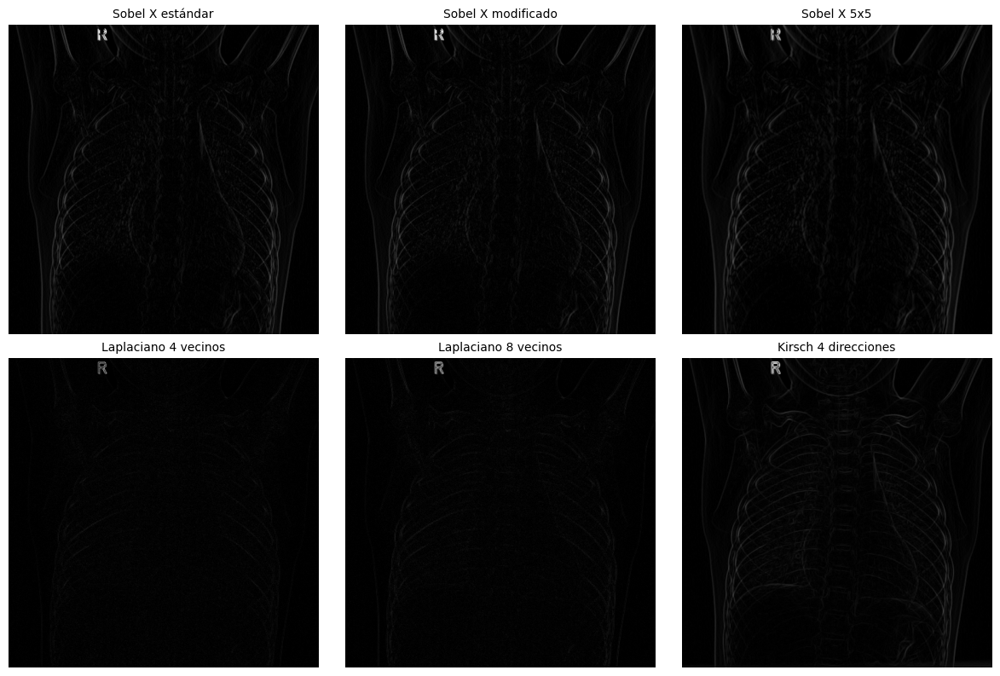

In [10]:
sobel_x_mod = [[-1, 0, 1], [-4, 0, 4], [-1, 0, 1]]
sobel_x_5 = [
    [-1, -2, 0, 2, 1],
    [-4, -8, 0, 8, 4],
    [-6, -12, 0, 12, 6],
    [-4, -8, 0, 8, 4],
    [-1, -2, 0, 2, 1],
]
laplaciano_8 = [[1, 1, 1], [1, -8, 1], [1, 1, 1]]
kirsch_4 = kirsch_mascaras()[0::2]

mostrar(
    [norm(gx), norm(conv(img, sobel_x_mod)), norm(conv(img, sobel_x_5)),
     norm(lap), norm(conv(img, laplaciano_8)), norm(kirsch(img, kirsch_4))],
    ["Sobel X estándar", "Sobel X modificado", "Sobel X 5x5",
     "Laplaciano 4 vecinos", "Laplaciano 8 vecinos", "Kirsch 4 direcciones"],
    cols=3,
)

## 4. Máscara personalizada

Se diseña una máscara de realce de 5x5. El centro tiene un peso positivo alto, el primer anillo refuerza el contraste local y el anillo exterior es negativo. Los coeficientes suman 1 después de dividir entre 8, por lo que el brillo promedio de la imagen se conserva.

Suma de la máscara: 1.0


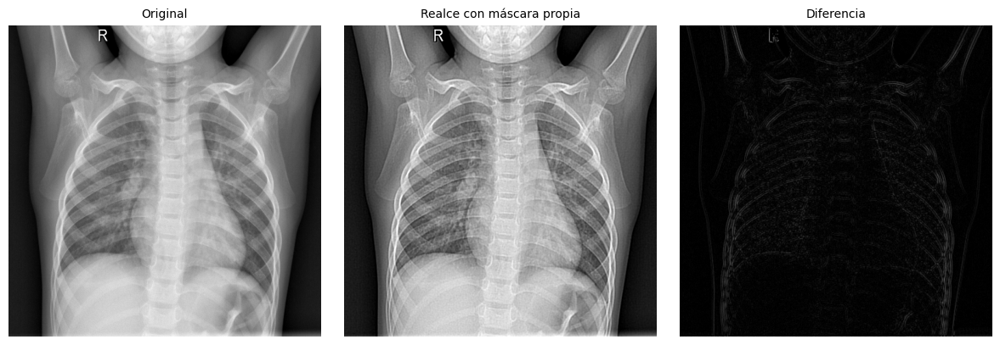

In [11]:
mascara_propia = np.array([
    [-1, -1, -1, -1, -1],
    [-1,  2,  2,  2, -1],
    [-1,  2,  8,  2, -1],
    [-1,  2,  2,  2, -1],
    [-1, -1, -1, -1, -1],
], dtype=np.float32) / 8.0

print("Suma de la máscara:", mascara_propia.sum())

realce = np.clip(conv(img, mascara_propia), 0, 255).astype(np.uint8)

mostrar([img, realce, cv2.absdiff(realce, img)],
        ["Original", "Realce con máscara propia", "Diferencia"], cols=3)

También se prueba una máscara de detección de bordes diagonales (45°):

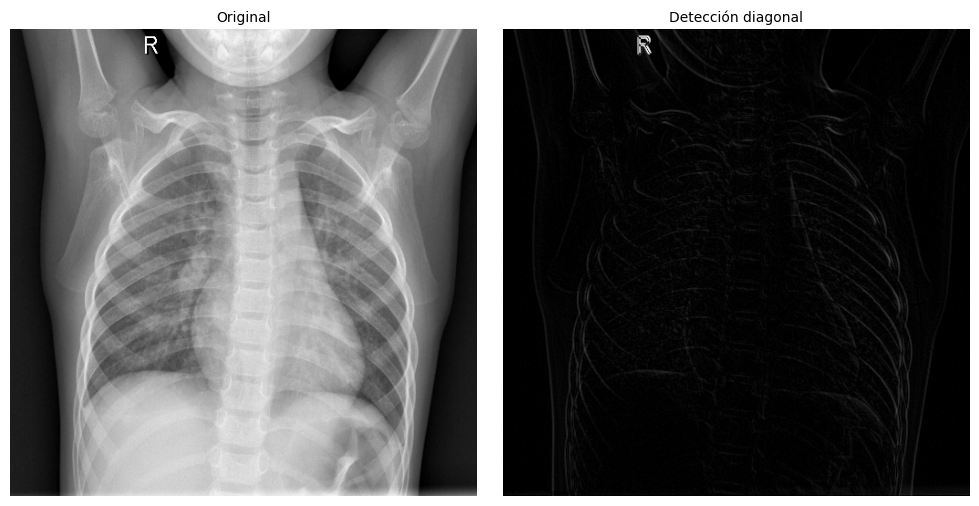

In [12]:
mascara_diag = [[0, 1, 2], [-1, 0, 1], [-2, -1, 0]]
mostrar([img, norm(conv(img, mascara_diag))], ["Original", "Detección diagonal"], cols=2, size=5)

## 5. Comparación y justificación del tamaño de kernel

Comparación final de los tres suavizados con los tres tamaños de kernel junto a la imagen original.

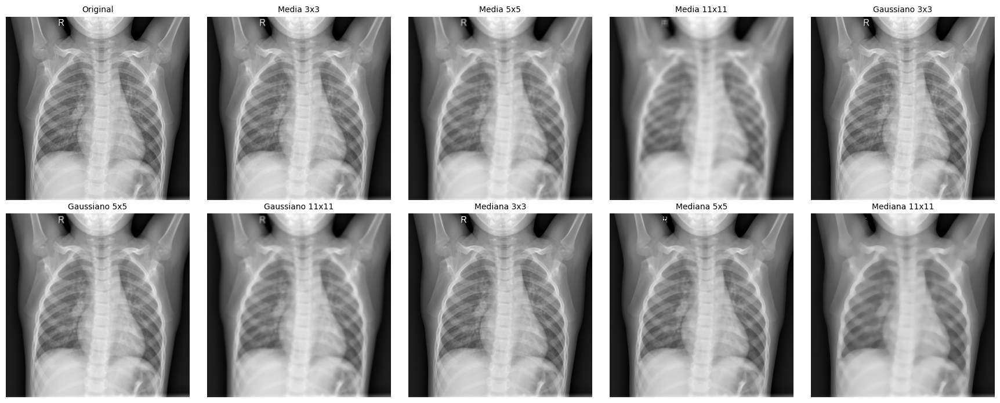

In [13]:
imgs = [img] + [suavizadas[(n, k)] for n in filtros for k in kernels]
titulos = ["Original"] + [f"{n} {k}x{k}" for n in filtros for k in kernels]
mostrar(imgs, titulos, cols=5, size=3.5)

**Justificación del tamaño de kernel**

Los valores de la tabla y las imágenes comparativas muestran lo siguiente:

- **3x3:** es el que menos altera la imagen. El MSE se queda entre 8.5 y 14.4 y las costillas, las clavículas, la columna y el contorno cardiaco siguen igual de definidos que en el original. Con la mediana la nitidez medida baja de 223.6 a 112.4, mientras que con la media baja a 19.2 y con el gaussiano a 26.3.
- **5x5:** el suavizado ya se nota a simple vista. La media 5x5 tiene un MSE de 31.5 y una nitidez de 6.2, y la textura fina de los pulmones se empieza a perder.
- **11x11:** la pérdida es grande. La media 11x11 llega a un MSE de 70.1 y una nitidez de 2.2, y las costillas y vasos pulmonares se ven desdibujados. En una radiografía esos detalles son los que importan para la interpretación, así que este tamaño no es adecuado.

**Elección:** para esta radiografía se justifica usar **3x3**, y 5x5 como máximo. El filtro que mejor conserva los bordes con kernels pequeños es la mediana, que tiene el menor MSE con 3x3 (8.55) y la mayor nitidez residual. Con kernels grandes se comporta distinto, porque la mediana 5x5 y 11x11 elimina por completo la letra "R" de la esquina, que es una marca delgada, igual que la media 11x11. El gaussiano 11x11 en cambio la conserva legible, porque pondera más los píxeles cercanos al centro y difumina menos que la media del mismo tamaño (MSE de 37.1 contra 70.1).

---
# Parte II: Filtros en el dominio de la frecuencia

## 1. Carga de las imágenes y transformada de Fourier

Se utilizan dos radiografías distintas (normal y con neumonía). Para cada una se calcula la FFT 2D, se centra el espectro con `fftshift` y se visualiza la magnitud en escala logarítmica.

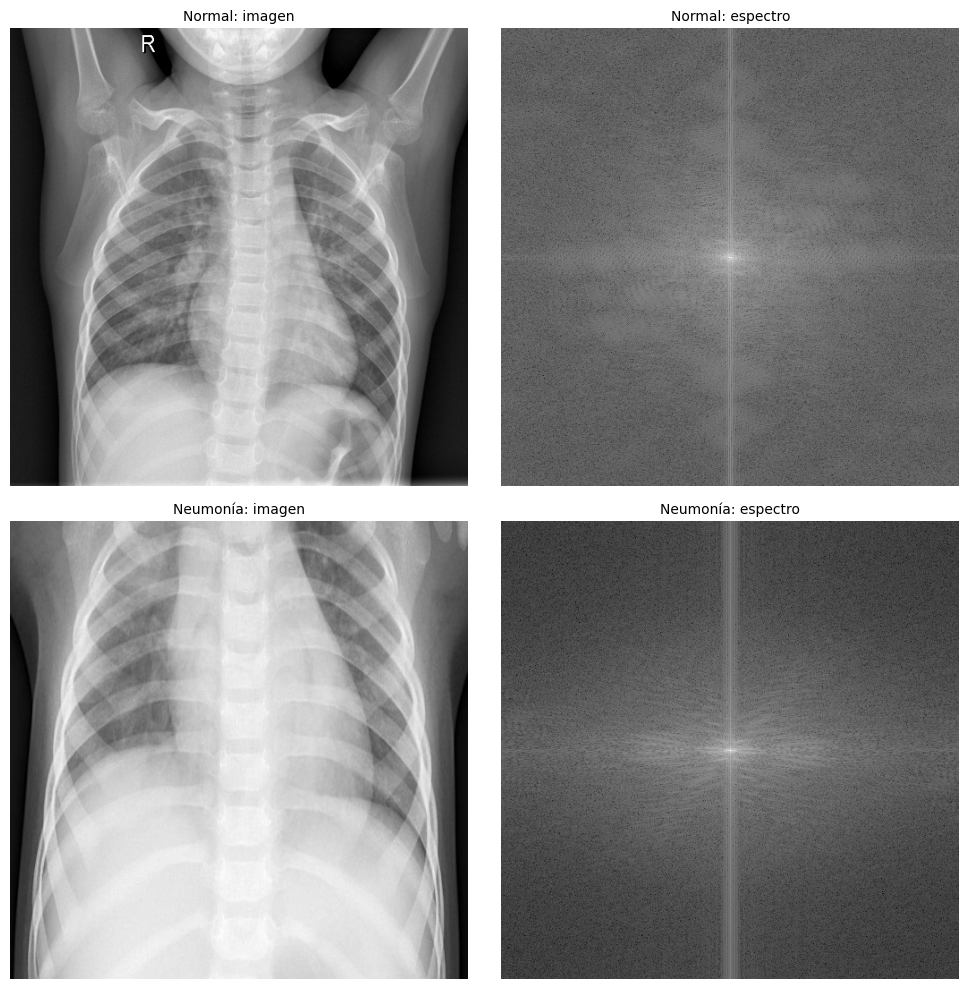

In [14]:
imgs2 = {"Normal": cargar(RUTA_1), "Neumonía": cargar(RUTA_2)}

def fft_centrada(im):
    return np.fft.fftshift(np.fft.fft2(im))

def espectro_log(F):
    return np.log1p(np.abs(F))

espectros = {n: fft_centrada(im) for n, im in imgs2.items()}

imgs, titulos = [], []
for n in imgs2:
    imgs += [imgs2[n], espectro_log(espectros[n])]
    titulos += [f"{n}: imagen", f"{n}: espectro"]
mostrar(imgs, titulos, cols=2, size=5)

## 2. Construcción de las máscaras

Las máscaras se generan con una malla de distancias al centro del espectro.

- **Pasa bajas circular:** deja pasar frecuencias dentro de un radio de corte.
- **Pasa altas circular:** complemento del pasa bajas.
- **Pasa altas en anillo:** deja pasar únicamente una banda entre dos radios, eliminando las frecuencias más bajas y las más altas.
- **Pasa altas en cruz:** bloquea una franja horizontal y vertical que pasa por el centro del espectro, lo que elimina la componente continua y las frecuencias a lo largo de los ejes.

In [15]:
filas, cols = TAM
cy, cx = filas // 2, cols // 2
Y, X = np.ogrid[:filas, :cols]
dist = np.sqrt((Y - cy) ** 2 + (X - cx) ** 2)

def pasa_bajas(r):
    return (dist <= r).astype(np.float32)

def pasa_altas(r):
    return (dist > r).astype(np.float32)

def anillo(r_int, r_ext):
    return ((dist >= r_int) & (dist <= r_ext)).astype(np.float32)

def cruz(ancho):
    m = np.ones((filas, cols), dtype=np.float32)
    m[cy - ancho:cy + ancho, :] = 0
    m[:, cx - ancho:cx + ancho] = 0
    return m

def aplicar(F, mascara):
    return np.abs(np.fft.ifft2(np.fft.ifftshift(F * mascara)))

def energia(F, mascara):
    return 100 * np.sum(np.abs(F * mascara) ** 2) / np.sum(np.abs(F) ** 2)

mascaras_bajas = {f"Pasa bajas r={r}": pasa_bajas(r) for r in (20, 50, 80)}
mascaras_altas = {
    "Pasa altas círculo r=10": pasa_altas(10),
    "Pasa altas círculo r=30": pasa_altas(30),
    "Pasa altas anillo 30-100": anillo(30, 100),
    "Pasa altas cruz": cruz(15),
}

## 3. Filtros pasa bajas con distintos radios

Para cada configuración se muestra la máscara, el espectro filtrado y la imagen reconstruida con la transformada inversa. También se reporta el porcentaje de energía del espectro que conserva cada máscara.
En los filtros pasa altas el resultado se muestra con el contraste estirado (se recorta al percentil 99.5), porque estas imágenes tienen muy poca energía y de otra forma se verían casi negras.

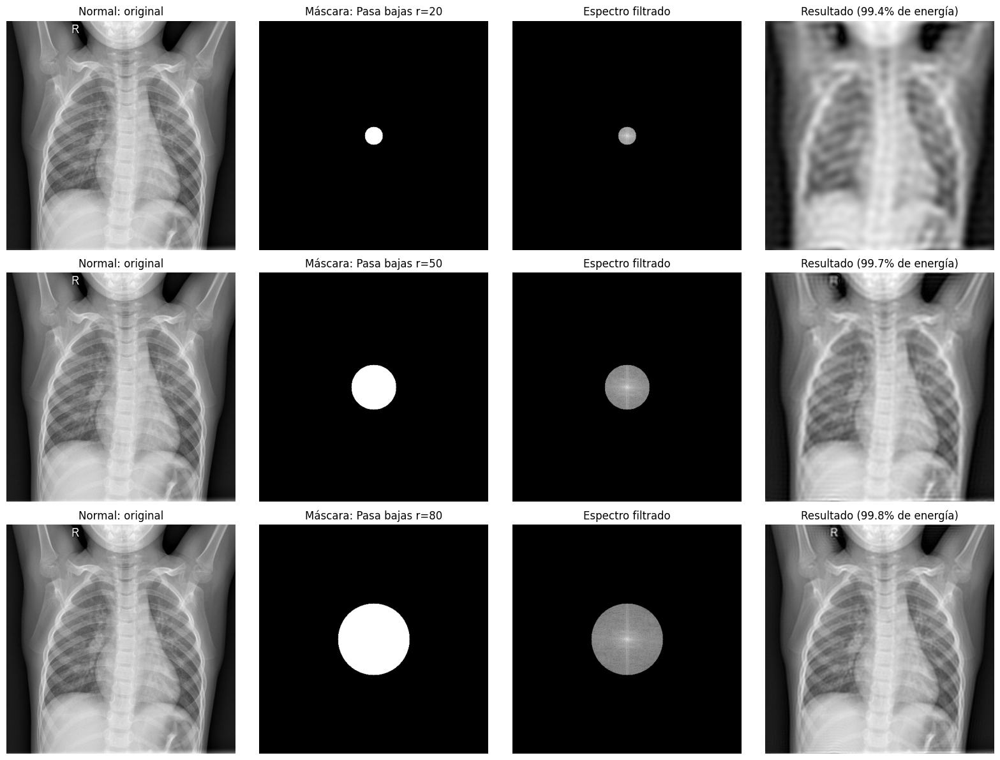

In [16]:
def vista(res, nombre):
    if nombre.startswith("Pasa altas"):
        return np.clip(res / np.percentile(res, 99.5), 0, 1)
    return res

def probar(nombre_img, mascaras):
    im, F = imgs2[nombre_img], espectros[nombre_img]
    n = len(mascaras)
    fig, ejes = plt.subplots(n, 4, figsize=(16, 4 * n))
    ejes = np.atleast_2d(ejes)
    for fila, (nom, m) in zip(ejes, mascaras.items()):
        res = aplicar(F, m)
        fila[0].imshow(im, cmap="gray");                 fila[0].set_title(f"{nombre_img}: original")
        fila[1].imshow(m, cmap="gray");                  fila[1].set_title(f"Máscara: {nom}")
        fila[2].imshow(espectro_log(F * m), cmap="gray"); fila[2].set_title("Espectro filtrado")
        fila[3].imshow(vista(res, nom), cmap="gray");                fila[3].set_title(f"Resultado ({energia(F, m):.1f}% de energía)")
        for ax in fila:
            ax.axis("off")
    plt.tight_layout()
    plt.show()

probar("Normal", mascaras_bajas)

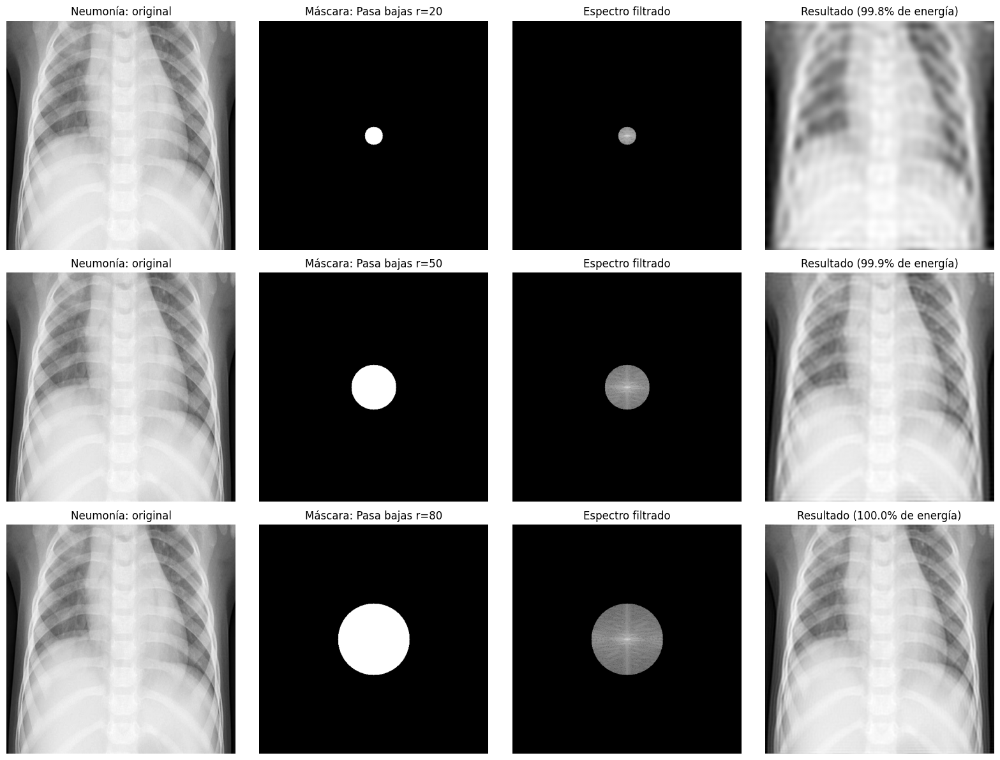

In [17]:
probar("Neumonía", mascaras_bajas)

## 4. Filtros pasa altas con distintas configuraciones

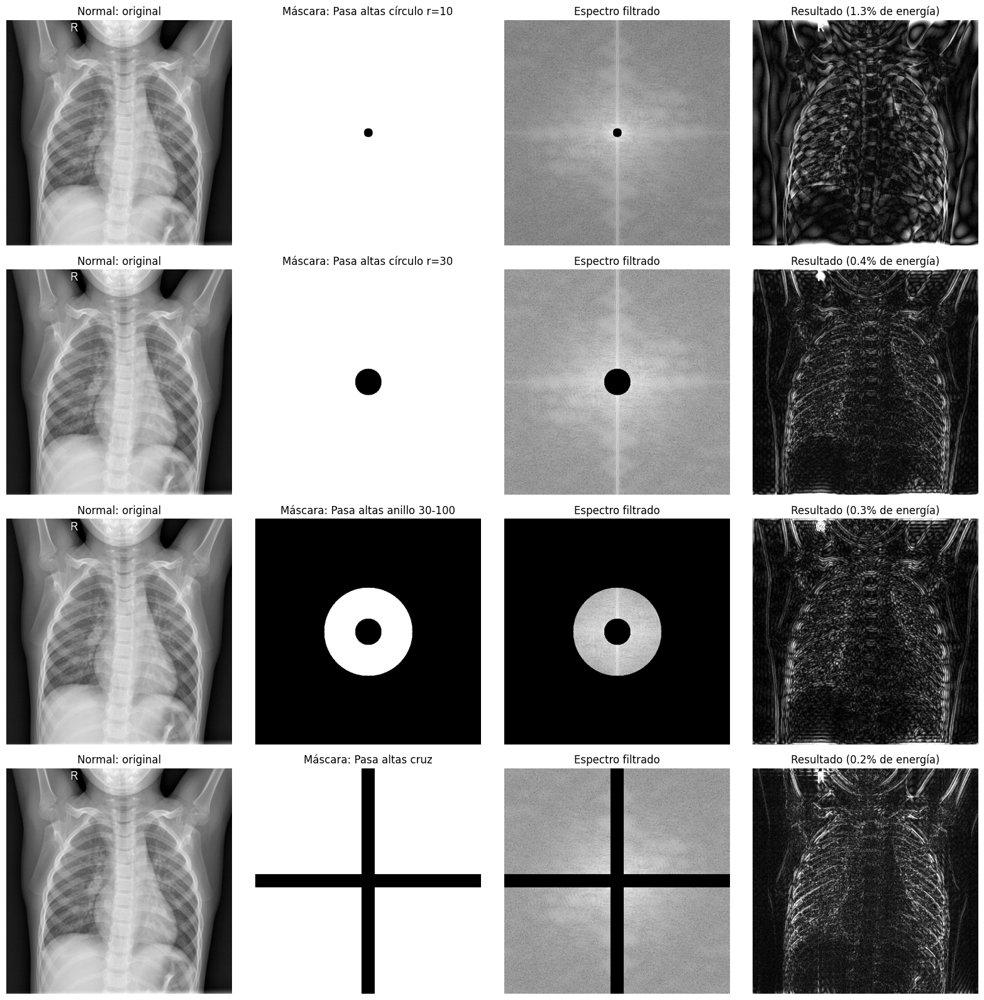

In [18]:
probar("Normal", mascaras_altas)

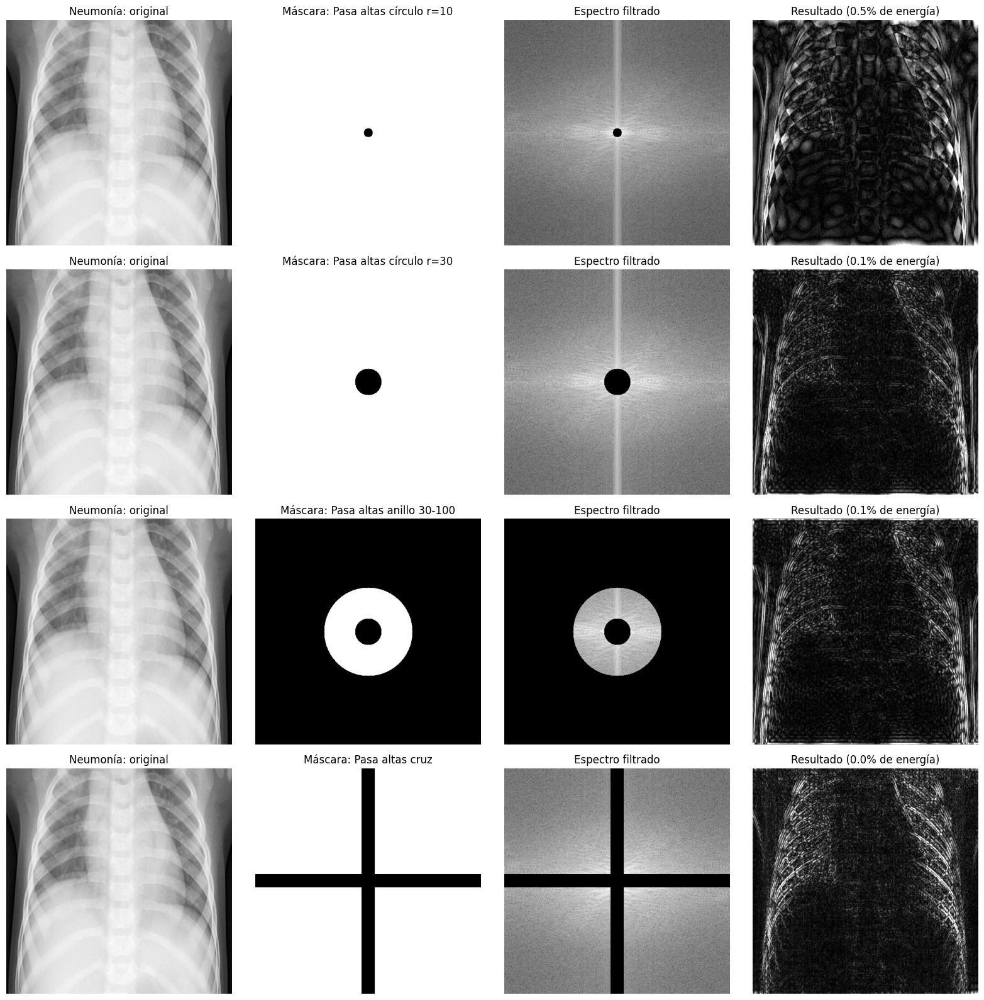

In [19]:
probar("Neumonía", mascaras_altas)

## 5. Comparación de resultados

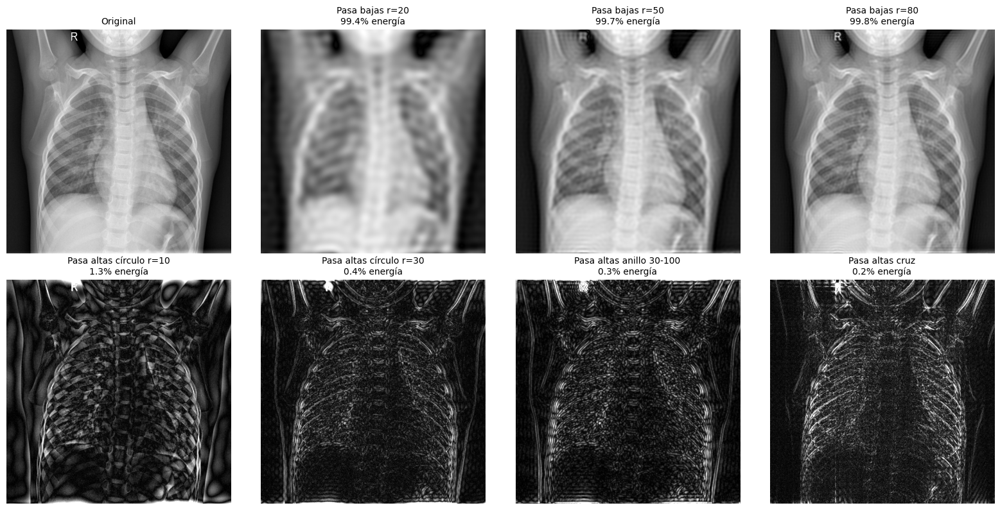

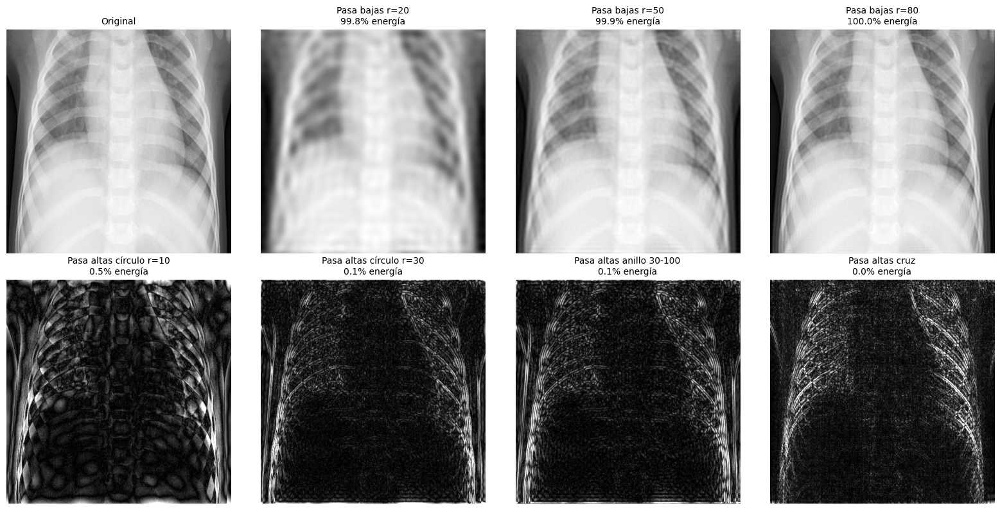

In [20]:
todas = {**mascaras_bajas, **mascaras_altas}
for n in imgs2:
    F = espectros[n]
    resultados = [imgs2[n]] + [vista(aplicar(F, m), k) for k, m in todas.items()]
    titulos = ["Original"] + [f"{k}\n{energia(F, m):.1f}% energía" for k, m in todas.items()]
    mostrar(resultados, titulos, cols=4, size=4)

**Análisis**

- **Pasa bajas:** con radio 20 la imagen queda muy borrosa. Solo se distinguen la silueta torácica, la columna y las zonas claras y oscuras, y las costillas aparecen como bandas difusas con artefactos de anillo alrededor de los bordes. Con radio 50 ya se recuperan costillas, clavículas y la letra "R", y con radio 80 el resultado es prácticamente igual al original. A menor radio, mayor pérdida de detalle fino.
- **Energía conservada:** el porcentaje de energía no refleja la pérdida visual. Con radio 20 se conserva el 99.4% de la energía en la imagen normal y el 99.8% en la de neumonía, aunque la imagen se ve muy degradada. Esto se debe a que casi toda la energía del espectro está en la componente continua y en las frecuencias más bajas, mientras que los detalles aportan muy poca.
- **Pasa altas circular:** con r=10 se elimina el brillo promedio y las zonas amplias de intensidad uniforme, y quedan los bordes de costillas, columna y diafragma. Con r=30 queda solo una línea fina en los bordes más marcados. Entre más grande el radio, menos estructura se conserva.
- **Pasa altas en anillo (30-100):** da un resultado muy parecido al pasa altas con r=30, porque las frecuencias mayores a 100 aportan poca energía. Además de los bordes, se aprecia algo de ruido y de textura fina.
- **Pasa altas en cruz:** el resultado es el más tenue (0.2% de energía en la imagen normal y 0.0% en la de neumonía). Al bloquear las frecuencias sobre los ejes horizontal y vertical se atenúan las estructuras orientadas en esas direcciones, y las costillas inclinadas son las que más destacan, sobre todo en la imagen con neumonía.
- **Normal vs. neumonía:** en la radiografía con neumonía las zonas de opacidad son regiones amplias y de brillo uniforme, es decir, información de baja frecuencia. Con el pasa bajas r=20 esas zonas se funden con el resto del pulmón y con los pasa altas casi desaparecen, y solo quedan los bordes de las costillas. En la imagen normal, los pasa altas también resaltan la letra "R", porque es una marca con bordes muy definidos.

---
## Conclusiones

- En el dominio espacial, el tamaño del kernel es una decisión entre reducir ruido y conservar detalle. En radiografías de tórax los kernels de 3x3 y 5x5 conservan las estructuras importantes, mientras que 11x11 las borra. La mediana conserva mejor los bordes con kernels pequeños, pero con kernels grandes elimina por completo estructuras delgadas como la marca "R".
- Las máscaras de bordes dependen de sus pesos y de su tamaño. Cambiar los coeficientes del Sobel, ampliarlo a 5x5, incluir las diagonales en el Laplaciano o reducir las direcciones del Kirsch modifica qué bordes se resaltan y con cuánta intensidad. La máscara de realce propia aumentó el contraste local sin cambiar el brillo promedio, porque sus coeficientes suman 1.
- En el dominio de la frecuencia, la información gruesa de la imagen está en las frecuencias bajas y los bordes en las altas. Un pasa bajas con radio pequeño desenfoca la imagen y un pasa altas deja solo los bordes, con muy poca energía.
- El porcentaje de energía conservada no sirve por sí solo para evaluar la calidad visual, porque la componente continua concentra casi toda la energía del espectro.
- Los filtros en frecuencia permiten controlar de forma más precisa qué se conserva (círculo, anillo, cruz), y los espaciales son más sencillos de aplicar cuando el efecto buscado es local.

## Referencias

1. Mooney, P. T. *Chest X-Ray Images (Pneumonia)*. Kaggle. https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
2. Repositorio de la clase, Dominio del Espacio. https://github.com/dilp90/PDI/tree/main/DominioDelEspacio
3. Notebook de la clase, Filtros con máscaras. https://github.com/dilp90/PDI/blob/main/DominioDelEspacio/PDI_8_FiltrosConMascaras.ipynb
4. Notebook de la clase, Fourier, pasa bajas y pasa altas. https://github.com/dilp90/PDI/blob/main/DominioDeLaFrecuencia/TransformadaFourier_FiltroPasaBajas_y_PasaAlta.ipynb
5. Documentación de OpenCV. https://docs.opencv.org/